# Proyecto 1 · Cancelaciones hoteleras

**¿Qué tienen en común las reservas que más se cancelan? ¿Podemos anticiparlas?**

En este notebook dejamos el análisis y los resultados. Los comentarios son cortos para que se pueda seguir el código. Cada gráfico y cada tabla llevan debajo una lectura breve de lo que muestran.

Trabajamos con **CRISP-DM**, siguiendo las etapas que vimos en clase. Usamos pandas para explorar y preparar la base, y comparamos tres modelos de clasificación.


## 1. Entender el problema

Para el hotel es útil saber qué reservas tienen más riesgo de cancelarse, por ejemplo para organizar mejor el seguimiento. Primero queremos entender **qué variables se relacionan con las cancelaciones** y luego comprobar si podemos predecirlas.

Nuestra variable objetivo es `is_canceled`: 0 significa que no se canceló y 1 que sí. Por eso estamos trabajando un problema de **clasificación**, no de predicción de precios o cantidades.

No sabemos cuánto cuesta cada alerta equivocada ni si contactar a un cliente evita que cancele. Por ahora medimos la calidad de la predicción, no un ahorro económico.


## 2. Conocer los datos

### 2.1. Abrimos el archivo

Empezamos con un `read_csv`, igual que en los ejercicios de clase. Dejamos el archivo `hotel_bookings.csv` en la misma carpeta del notebook.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Primero leemos la base y miramos qué contiene.
df = pd.read_csv("hotel_bookings.csv")
print("Reservas:", len(df))
print("Columnas:", df.shape[1])
display(df.head())


Reservas: 119390
Columnas: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 2.2. ¿Cómo está la calidad de la información?

Revisamos tipos de datos, faltantes, valores llamativos y filas exactamente iguales. No borramos reservas idénticas: sin un identificador único no sabemos si son errores o reservas diferentes.

In [2]:
print("Tipos de variables:")
df.info()

print("\nVariables con datos faltantes:")
nulos = df.isna().sum()
display(nulos[nulos > 0].sort_values(ascending=False))

print("\nFilas exactamente iguales:", df.duplicated().sum())
print("Reservas sin huéspedes informados:",
      (df[["adults", "children", "babies"]].fillna(0).sum(axis=1) == 0).sum())
print("Tarifas negativas:", (df["adr"] < 0).sum())

# Una mirada general a las variables numéricas.
display(df.describe().round(2))
print("No eliminamos filas en este paso. Primero queremos entender qué tenemos.")

Tipos de variables:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal   

company     112593
agent        16340
country        488
children         4
dtype: int64


Filas exactamente iguales:

 31994
Reservas sin huéspedes informados: 180
Tarifas negativas: 1


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119386.0,119390.00,119390.00,119390.00,119390.00,119390.00,103050.00,6797.00,119390.00,119390.00,119390.00,119390.00
mean,0.37,104.01,2016.16,27.17,15.80,0.93,2.50,1.86,0.1,0.01,0.03,0.09,0.14,0.22,86.69,189.27,2.32,101.83,0.06,0.57
std,0.48,106.86,0.71,13.61,8.78,1.00,1.91,0.58,0.4,0.10,0.18,0.84,1.50,0.65,110.77,131.66,17.59,50.54,0.25,0.79
min,0.00,0.00,2015.00,1.00,1.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00,6.00,0.00,-6.38,0.00,0.00
25%,0.00,18.00,2016.00,16.00,8.00,0.00,1.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,9.00,62.00,0.00,69.29,0.00,0.00
50%,0.00,69.00,2016.00,28.00,16.00,1.00,2.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,14.00,179.00,0.00,94.58,0.00,0.00
75%,1.00,160.00,2017.00,38.00,23.00,2.00,3.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,229.00,270.00,0.00,126.00,0.00,1.00
max,1.00,737.00,2017.00,53.00,31.00,19.00,50.00,55.00,10.0,10.00,1.00,26.00,72.00,21.00,535.00,543.00,391.00,5400.00,8.00,5.00


No eliminamos filas en este paso. Primero queremos entender qué tenemos.


### 2.3. ¿Cómo son las reservas?

Miramos la anticipación, la duración de la estadía y la tarifa diaria. Son tres gráficos descriptivos: por sí solos **no** dicen qué causa una cancelación.

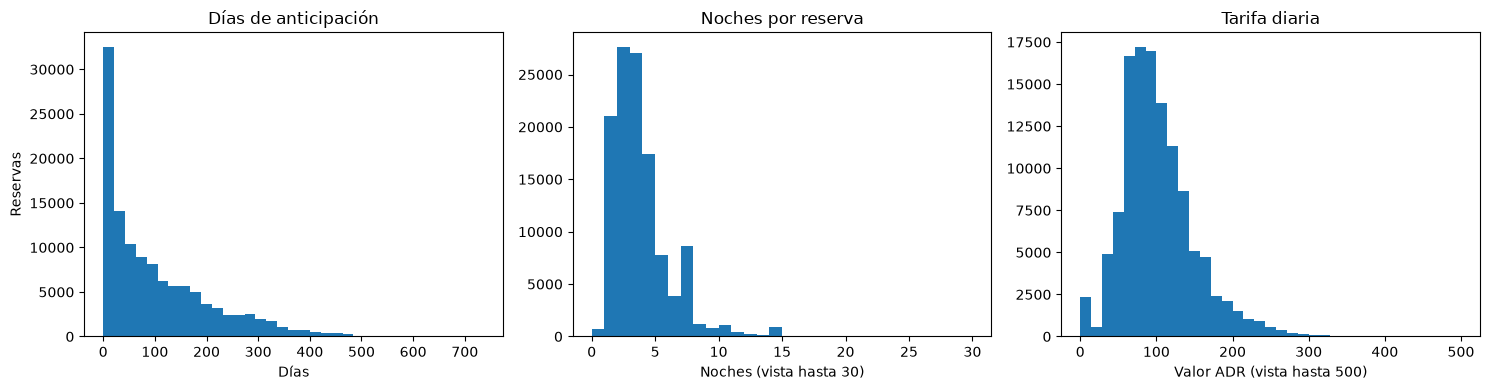

Anticipación: la mitad de las reservas tiene 69 días o menos.
Duración: la mitad tiene 3 noches o menos.
Tarifa: la mediana es 94.6 en la unidad original del CSV.
En los gráficos de noches y tarifa acotamos la vista; no borramos los valores altos.


In [3]:
df["noches_totales"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(df["lead_time"], bins=35)
ejes[0].set_title("Días de anticipación")
ejes[0].set_xlabel("Días")
ejes[0].set_ylabel("Reservas")

ejes[1].hist(df["noches_totales"].clip(upper=30), bins=30)
ejes[1].set_title("Noches por reserva")
ejes[1].set_xlabel("Noches (vista hasta 30)")

ejes[2].hist(df["adr"].clip(lower=0, upper=500), bins=35)
ejes[2].set_title("Tarifa diaria")
ejes[2].set_xlabel("Valor ADR (vista hasta 500)")
plt.tight_layout()
plt.show()

print("Anticipación: la mitad de las reservas tiene", round(df["lead_time"].median()), "días o menos.")
print("Duración: la mitad tiene", round(df["noches_totales"].median()), "noches o menos.")
print("Tarifa: la mediana es", round(df["adr"].median(), 1), "en la unidad original del CSV.")
print("En los gráficos de noches y tarifa acotamos la vista; no borramos los valores altos.")

### 2.4. ¿Cuántas reservas se cancelaron?

Este dato es nuestra referencia para interpretar el modelo. Si una clase es más frecuente, acertar muchas veces no necesariamente significa detectar bien las cancelaciones.

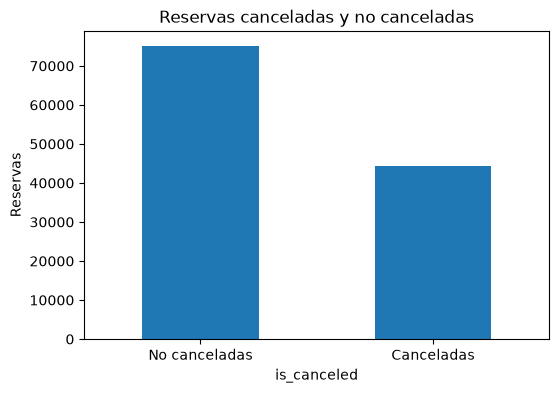

Se cancelaron 44224 de 119390 reservas.
Eso equivale al 37.0% del total.
El gráfico nos deja ver que hay más reservas no canceladas que canceladas.


In [4]:
conteos = df["is_canceled"].value_counts().sort_index()
conteos.plot(kind="bar", figsize=(6, 4), title="Reservas canceladas y no canceladas")
plt.xticks([0, 1], ["No canceladas", "Canceladas"], rotation=0)
plt.ylabel("Reservas")
plt.show()

print("Se cancelaron", int(conteos[1]), "de", len(df), "reservas.")
print("Eso equivale al", f"{df['is_canceled'].mean():.1%}", "del total.")
print("El gráfico nos deja ver que hay más reservas no canceladas que canceladas.")

### 2.5. ¿Qué grupos se cancelan más?

Comparamos porcentajes de cancelación, no solo cantidades. Por ejemplo, si un grupo tiene muchas reservas también puede tener muchas cancelaciones en números absolutos, sin que su tasa sea necesariamente mayor.

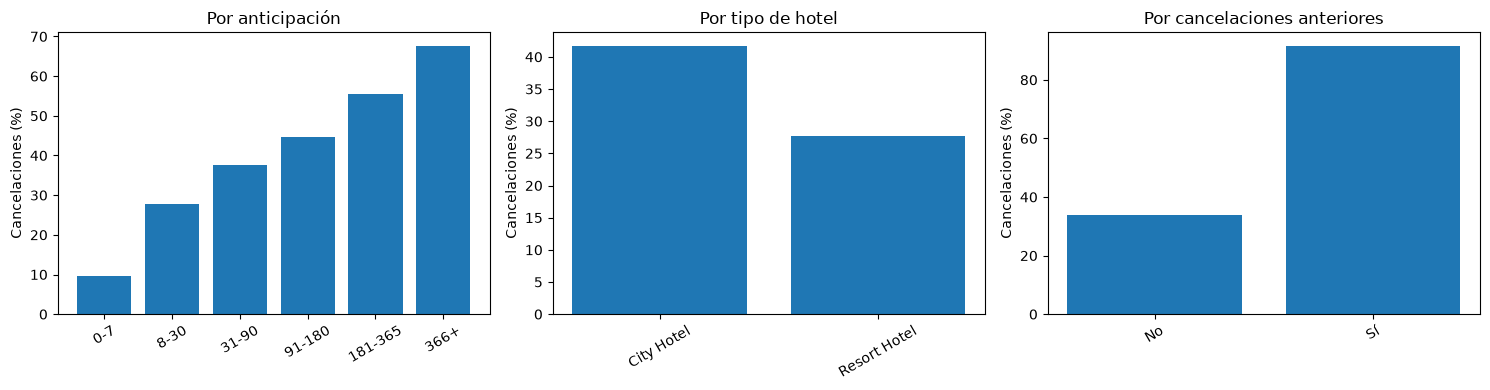

En el gráfico de anticipación el grupo 366+ tiene la tasa más alta: 67.7% en 3148 reservas.
En el gráfico de tipo de hotel el grupo City Hotel tiene la tasa más alta: 41.7% en 79330 reservas.
En el gráfico de cancelaciones anteriores el grupo Sí tiene la tasa más alta: 91.6% en 6484 reservas.
Estas son relaciones observadas; no prueban que una característica cause la cancelación.


In [5]:
# Agrupamos la anticipación para comparar reservas similares.
limites = [-1, 7, 30, 90, 180, 365, float("inf")]
etiquetas = ["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
df["rango_anticipacion"] = pd.cut(df["lead_time"], bins=limites, labels=etiquetas)
df["tuvo_cancelaciones_previas"] = np.where(df["previous_cancellations"] > 0, "Sí", "No")

# Guardamos las tablas porque las vamos a utilizar para explicar los gráficos.
tasas = {}
columnas_eda = ["rango_anticipacion", "hotel", "tuvo_cancelaciones_previas",
                "market_segment", "distribution_channel", "is_repeated_guest"]
for columna in columnas_eda:
    tabla = df.groupby(columna, observed=True)["is_canceled"].agg(["count", "mean"])
    tabla.columns = ["reservas", "tasa_cancelacion"]
    tasas[columna] = tabla

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, columna, titulo in zip(
    ejes,
    ["rango_anticipacion", "hotel", "tuvo_cancelaciones_previas"],
    ["Por anticipación", "Por tipo de hotel", "Por cancelaciones anteriores"]
):
    tabla = tasas[columna]
    eje.bar(tabla.index.astype(str), tabla["tasa_cancelacion"] * 100)
    eje.set_title(titulo)
    eje.set_ylabel("Cancelaciones (%)")
    eje.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

for columna, nombre in [("rango_anticipacion", "anticipación"),
                        ("hotel", "tipo de hotel"),
                        ("tuvo_cancelaciones_previas", "cancelaciones anteriores")]:
    tabla = tasas[columna]
    mayor = tabla["tasa_cancelacion"].idxmax()
    porcentaje = tabla.loc[mayor, "tasa_cancelacion"]
    cantidad = int(tabla.loc[mayor, "reservas"])
    print("En el gráfico de", nombre, "el grupo", mayor,
          "tiene la tasa más alta:", f"{porcentaje:.1%}", "en", cantidad, "reservas.")
print("Estas son relaciones observadas; no prueban que una característica cause la cancelación.")

### 2.6. Segmentos y meses de llegada

Miramos si los segmentos comerciales se comportan distinto y cómo cambia el porcentaje de cancelación por mes. Ojo: la base no cubre los mismos meses en todos los años.

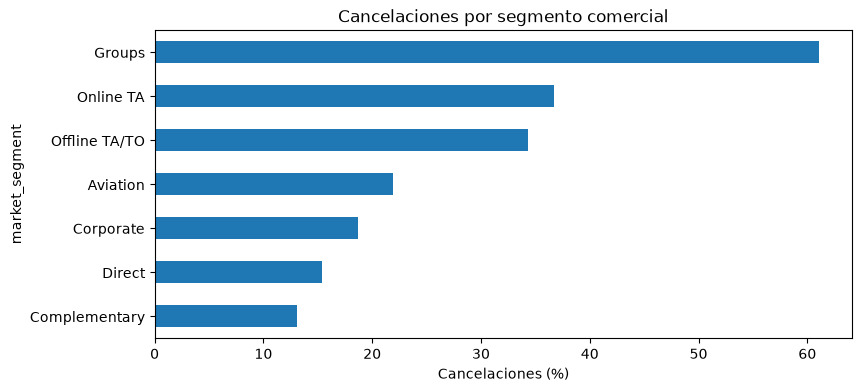

El segmento con mayor tasa entre los grupos de al menos 100 reservas es Groups con 61.1% .
No basta con mirar el porcentaje: también importa cuántas reservas tiene cada grupo.


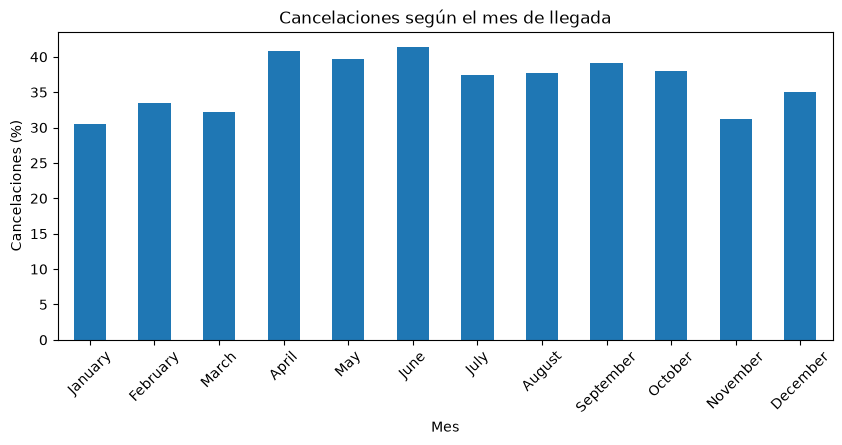

El mes con mayor tasa en esta base es June con 41.5% .
Esto describe el periodo disponible, no demuestra un patrón permanente de temporada.


In [6]:
segmentos = tasas["market_segment"]
segmentos = segmentos[segmentos["reservas"] >= 100].sort_values("tasa_cancelacion")
(segmentos["tasa_cancelacion"] * 100).plot(kind="barh", figsize=(9, 4),
    title="Cancelaciones por segmento comercial")
plt.xlabel("Cancelaciones (%)")
plt.show()
mayor_segmento = segmentos["tasa_cancelacion"].idxmax()
print("El segmento con mayor tasa entre los grupos de al menos 100 reservas es",
      mayor_segmento, "con", f"{segmentos.loc[mayor_segmento, 'tasa_cancelacion']:.1%}", ".")
print("No basta con mirar el porcentaje: también importa cuántas reservas tiene cada grupo.")

meses = ["January", "February", "March", "April", "May", "June",
         "July", "August", "September", "October", "November", "December"]
por_mes = df.groupby("arrival_date_month")["is_canceled"].mean().reindex(meses)
(por_mes * 100).plot(kind="bar", figsize=(10, 4),
    title="Cancelaciones según el mes de llegada")
plt.ylabel("Cancelaciones (%)")
plt.xlabel("Mes")
plt.xticks(rotation=45)
plt.show()
print("El mes con mayor tasa en esta base es", por_mes.idxmax(),
      "con", f"{por_mes.max():.1%}", ".")
print("Esto describe el periodo disponible, no demuestra un patrón permanente de temporada.")

### 2.7. Relaciones entre variables numéricas

En este mapa cada casilla muestra la correlación entre dos variables. Los números van de **-1 a 1**: el signo indica la dirección y los valores más cercanos a -1 o 1 muestran una relación lineal más fuerte. Así no tenemos que adivinar solo por el color.

Ojo: correlación no es lo mismo que causa, y una relación cercana a cero no descarta que exista otro tipo de relación.

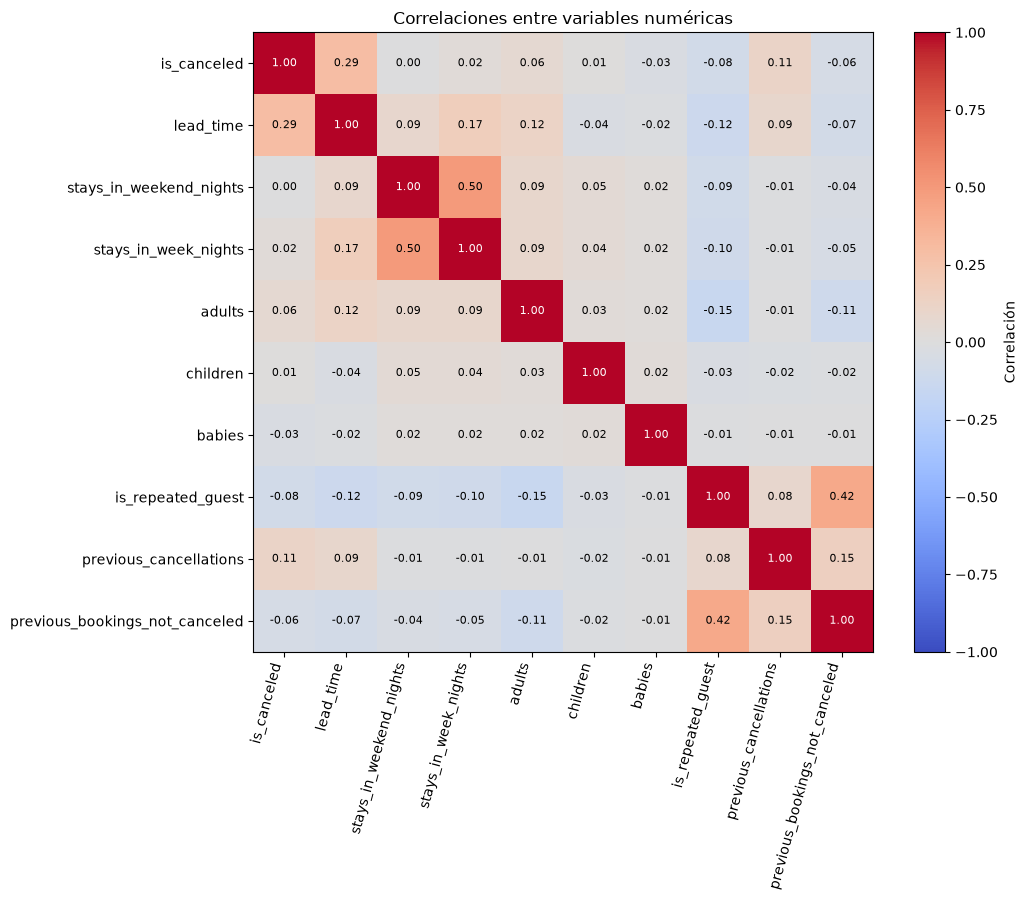

Entre las variables numéricas mostradas, la que tiene mayor relación lineal en valor absoluto con la cancelación es lead_time con 0.293 .
Esto no sirve por sí solo para decidir qué variable debe usar el modelo.


In [7]:
variables_corr = ["is_canceled", "lead_time", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled"]

correlaciones = df[variables_corr].corr()
fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(correlaciones, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(imagen, ax=ax, label="Correlación")
ax.set_xticks(range(len(variables_corr)))
ax.set_yticks(range(len(variables_corr)))
ax.set_xticklabels(variables_corr, rotation=75, ha="right")
ax.set_yticklabels(variables_corr)
ax.set_title("Correlaciones entre variables numéricas")

# Ponemos el valor dentro de cada casilla para no depender solo del color.
for fila in range(len(variables_corr)):
    for columna in range(len(variables_corr)):
        valor = correlaciones.iloc[fila, columna]
        valor_mostrar = 0 if abs(valor) < 0.005 else valor
        color_texto = "white" if abs(valor) >= 0.6 else "black"
        ax.text(columna, fila, f"{valor_mostrar:.2f}", ha="center", va="center",
                fontsize=8, color=color_texto)

plt.tight_layout()
plt.show()

relaciones = correlaciones["is_canceled"].drop("is_canceled").abs().sort_values(ascending=False)
print("Entre las variables numéricas mostradas, la que tiene mayor relación lineal",
      "en valor absoluto con la cancelación es", relaciones.index[0],
      "con", round(relaciones.iloc[0], 3), ".")
print("Esto no sirve por sí solo para decidir qué variable debe usar el modelo.")

## 3. Preparar los datos

### 3.1. Qué variables usamos y cómo separamos los periodos

Nos quedamos con 15 variables que pueden servir para anticipar cancelaciones. No incluimos `reservation_status` porque allí ya aparece el resultado que queremos predecir.

Separamos la base por **fecha prevista de llegada**: primero entrenamos, después validamos y finalmente probamos. Así evitamos usar las reservas del último periodo para elegir el modelo.

Una limitación que debemos contar: la fecha de llegada **no es** la fecha en que se hizo la reserva. Por eso la separación no reproduce exactamente lo que el hotel sabía en cada momento.


In [8]:
numericas = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled"]
categoricas = ["hotel", "arrival_date_month", "meal", "market_segment",
    "distribution_channel", "reserved_room_type"]
variables = numericas + categoricas

# Convertimos el mes escrito en inglés a su número.
numero_mes = {mes: i + 1 for i, mes in enumerate(meses)}
df["fecha_llegada"] = pd.to_datetime(dict(
    year=df["arrival_date_year"],
    month=df["arrival_date_month"].map(numero_mes),
    day=df["arrival_date_day_of_month"]
))

entrenamiento = df[df["fecha_llegada"] < "2016-07-01"].copy()
validacion = df[(df["fecha_llegada"] >= "2016-07-01") &
                (df["fecha_llegada"] < "2017-01-01")].copy()
prueba = df[df["fecha_llegada"] >= "2017-01-01"].copy()

periodos = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "reservas": [len(entrenamiento), len(validacion), len(prueba)],
    "tasa_cancelacion": [entrenamiento["is_canceled"].mean(),
                          validacion["is_canceled"].mean(),
                          prueba["is_canceled"].mean()]
})
display(periodos.round(3))
assert len(entrenamiento) + len(validacion) + len(prueba) == len(df)
print("El conjunto de prueba se guardará sin usarlo para escoger el modelo.")

,conjunto,reservas,tasa_cancelacion
0,Entrenamiento,49157,0.358
1,Validación,29546,0.369
2,Prueba,40687,0.387


El conjunto de prueba se guardará sin usarlo para escoger el modelo.


### 3.2. Dejamos la información lista

Revisamos números faltantes y columnas con texto. Usamos `fillna()` para completar los datos que necesita el modelo, y `get_dummies()` para convertir categorías en columnas de ceros y unos. Los valores usados para completar y escalar salen **solo del entrenamiento**, para no mirar por adelantado la validación o la prueba.


In [9]:
X_ent = entrenamiento[variables].copy()
X_val = validacion[variables].copy()
X_test = prueba[variables].copy()
y_ent = entrenamiento["is_canceled"]
y_val = validacion["is_canceled"]
y_test = prueba["is_canceled"]

# Si falta un número, usamos la mediana del conjunto de entrenamiento.
medianas = X_ent[numericas].median()
for tabla in [X_ent, X_val, X_test]:
    tabla[numericas] = tabla[numericas].fillna(medianas)
    tabla[categoricas] = tabla[categoricas].fillna("Sin dato")

# La regresión logística necesita magnitudes comparables.
promedios = X_ent[numericas].mean()
desviaciones = X_ent[numericas].std().replace(0, 1)
for tabla in [X_ent, X_val, X_test]:
    tabla[numericas] = (tabla[numericas] - promedios) / desviaciones

# Convertimos las categorías en columnas 0/1.
X_ent = pd.get_dummies(X_ent, columns=categoricas, dtype=int)
X_val = pd.get_dummies(X_val, columns=categoricas, dtype=int)
X_test = pd.get_dummies(X_test, columns=categoricas, dtype=int)

# Las tres tablas deben tener exactamente las mismas columnas.
X_val = X_val.reindex(columns=X_ent.columns, fill_value=0)
X_test = X_test.reindex(columns=X_ent.columns, fill_value=0)
print("Variables originales:", len(variables))
print("Columnas después de convertir categorías:", X_ent.shape[1])
print("Ya podemos entrenar sin datos faltantes ni columnas de texto.")

Variables originales: 15
Columnas después de convertir categorías: 51
Ya podemos entrenar sin datos faltantes ni columnas de texto.


## 4. Entrenamos y comparamos los modelos

Probamos **regresión logística, árbol de decisión y Random Forest**. Son los tres modelos mencionados en el ejemplo de modelado de la clase 2.

Esta vez escogeremos el modelo por **F1 en validación**, siguiendo el enfoque visto en clase. F1 combina precisión y recall: nos ayuda a no elegir un modelo que detecte muchas cancelaciones, pero produzca casi puras falsas alarmas. También mostramos exactitud y ROC-AUC como información adicional.

El umbral sirve para decidir desde qué probabilidad marcamos una reserva como riesgosa. Lo ajustamos con **validación**, nunca con el periodo de prueba.


In [10]:
# Los tres modelos trabajan con las mismas reservas y las mismas variables.
modelos = {
    "Regresión logística": LogisticRegression(max_iter=1000, random_state=42),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=120, max_depth=11,
        min_samples_leaf=40, random_state=42, n_jobs=-1)
}

resultados = []
modelos_entrenados = {}
curvas_f1 = {}
umbrales = np.arange(0.10, 0.91, 0.05)

for nombre, modelo in modelos.items():
    modelo.fit(X_ent, y_ent)
    prob_val = modelo.predict_proba(X_val)[:, 1]
    modelos_entrenados[nombre] = modelo

    # Probamos varios umbrales y nos quedamos con el de mejor F1 en validación.
    puntajes_f1 = []
    for umbral in umbrales:
        pred_val = (prob_val >= umbral).astype(int)
        puntajes_f1.append(f1_score(y_val, pred_val))
    curvas_f1[nombre] = puntajes_f1
    mejor_umbral = float(umbrales[np.argmax(puntajes_f1)])
    pred_val = (prob_val >= mejor_umbral).astype(int)

    # También miramos cómo quedó en entrenamiento: nos sirve para hablar de sobreajuste.
    prob_ent = modelo.predict_proba(X_ent)[:, 1]
    pred_ent = (prob_ent >= mejor_umbral).astype(int)
    resultados.append({
        "Modelo": nombre,
        "Umbral": mejor_umbral,
        "F1 entrenamiento": f1_score(y_ent, pred_ent),
        "F1 validación": f1_score(y_val, pred_val),
        "Exactitud": accuracy_score(y_val, pred_val),
        "Precisión": precision_score(y_val, pred_val, zero_division=0),
        "Recall": recall_score(y_val, pred_val, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob_val),
        "% alertas": pred_val.mean()
    })
    print("Entrenamos:", nombre)

comparacion = pd.DataFrame(resultados).sort_values("F1 validación", ascending=False)
display(comparacion.round(4))
modelo_elegido = comparacion.iloc[0]["Modelo"]
umbral_elegido = float(comparacion.iloc[0]["Umbral"])
modelo_final = modelos_entrenados[modelo_elegido]
print("Elegimos", modelo_elegido, "por su F1 en validación.")
print("El umbral que mejor funcionó fue", round(umbral_elegido, 2), ".")


Entrenamos: Regresión logística
Entrenamos: Árbol de decisión


Entrenamos: Random Forest


,Modelo,Umbral,F1 entrenamiento,F1 validación,Exactitud,Precisión,Recall,ROC-AUC,% alertas
2,Random Forest,0.25,0.6569,0.6111,0.5959,0.4736,0.8612,0.7102,0.6705
1,Árbol de decisión,0.30,0.6437,0.6013,0.5648,0.4540,0.8899,0.6827,0.7228
0,Regresión logística,0.15,0.5743,0.5755,0.4982,0.4182,0.9227,0.6806,0.8135


Elegimos Random Forest por su F1 en validación.
El umbral que mejor funcionó fue 0.25 .


### 4.1. ¿Qué nos dicen los gráficos de validación?

El primero compara los modelos con F1. El segundo muestra cómo cambia el F1 cuando bajamos o subimos el umbral de alerta. Después de elegir el modelo, no cambiamos la decisión mirando los resultados de prueba.


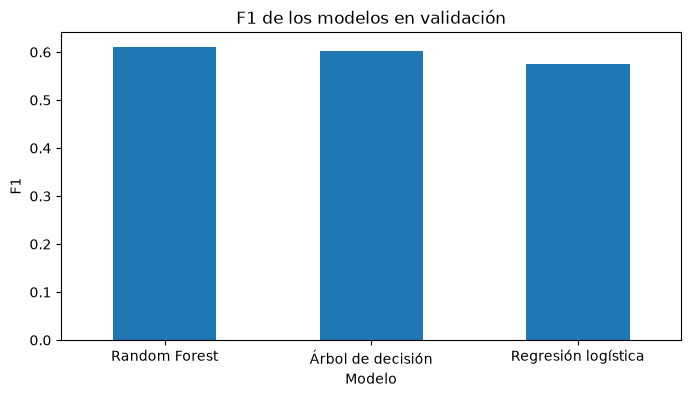

En este gráfico el mayor F1 lo obtuvo Random Forest con 0.611 .
Ese resultado nos ayuda a escoger, pero todavía no dice si el seguimiento sería rentable.


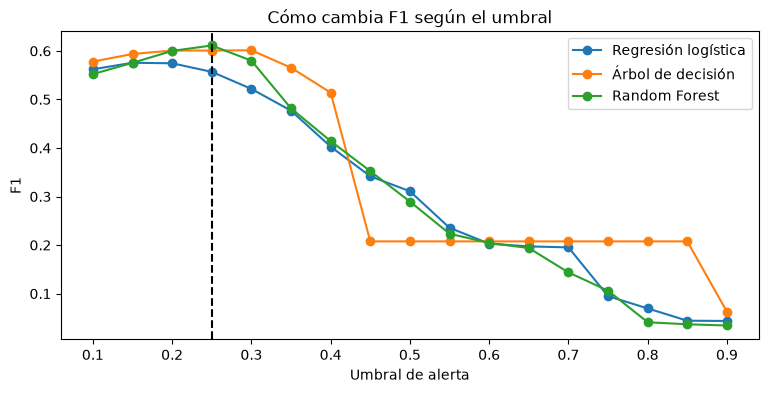

El valor escogido es 0.25 . Moverlo cambia cuántas reservas marcamos y cuántas alertas fallan.


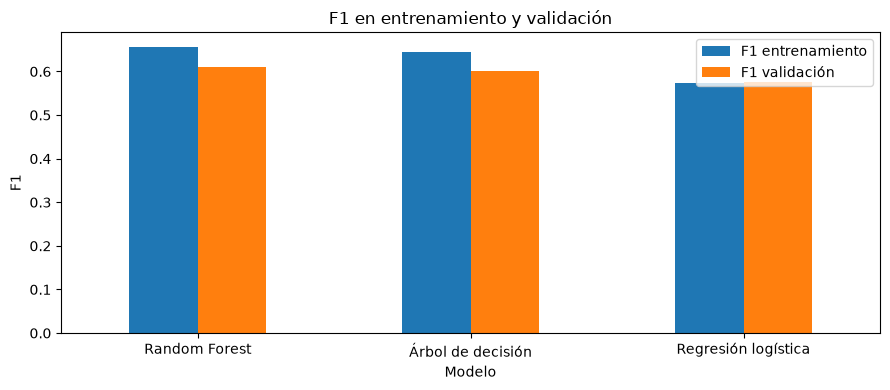

Random Forest: diferencia de F1 entrenamiento - validación = +0.046.
Árbol de decisión: diferencia de F1 entrenamiento - validación = +0.042.
Regresión logística: diferencia de F1 entrenamiento - validación = -0.001.
Una diferencia grande podría ser señal de sobreajuste; no la usamos sola para afirmarlo.


In [11]:
comparacion.plot(x="Modelo", y="F1 validación", kind="bar",
    figsize=(8, 4), legend=False, title="F1 de los modelos en validación")
plt.ylabel("F1")
plt.xticks(rotation=0)
plt.show()
print("En este gráfico el mayor F1 lo obtuvo", modelo_elegido,
      "con", round(comparacion.iloc[0]["F1 validación"], 3), ".")
print("Ese resultado nos ayuda a escoger, pero todavía no dice si el seguimiento sería rentable.")

plt.figure(figsize=(9, 4))
for nombre in modelos:
    plt.plot(umbrales, curvas_f1[nombre], marker="o", label=nombre)
plt.axvline(umbral_elegido, linestyle="--", color="black")
plt.title("Cómo cambia F1 según el umbral")
plt.xlabel("Umbral de alerta")
plt.ylabel("F1")
plt.legend()
plt.show()
print("El valor escogido es", round(umbral_elegido, 2),
      ". Moverlo cambia cuántas reservas marcamos y cuántas alertas fallan.")

# Comparamos F1 de entrenamiento con el de validación para revisar sobreajuste.
comparacion[["Modelo", "F1 entrenamiento", "F1 validación"]].set_index("Modelo").plot(
    kind="bar", figsize=(9, 4), title="F1 en entrenamiento y validación")
plt.ylabel("F1")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
for _, fila in comparacion.iterrows():
    diferencia = fila["F1 entrenamiento"] - fila["F1 validación"]
    print(f"{fila['Modelo']}: diferencia de F1 entrenamiento - validación = {diferencia:+.3f}.")
print("Una diferencia grande podría ser señal de sobreajuste; no la usamos sola para afirmarlo.")


## 5. Revisamos el modelo en el periodo de prueba

Llegamos a la parte final: usamos reservas posteriores que habíamos dejado separadas. Aquí solo **evaluamos**; no volvemos a escoger ni el modelo ni el umbral por sus resultados.


,Modelo,Umbral,Exactitud,Precisión,Recall,F1,ROC-AUC,% alertas
0,Random Forest,0.25,0.5841,0.4799,0.8925,0.6242,0.6991,0.7197


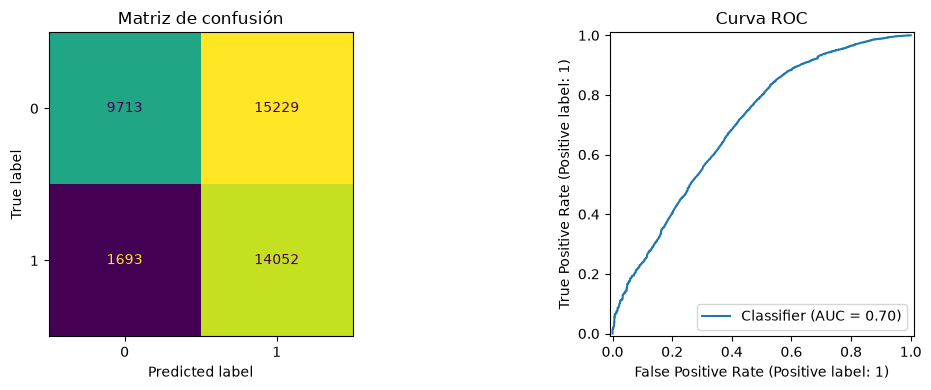

En la matriz vemos que detectamos 14052 cancelaciones, pero se escaparon 1693 .
También marcamos 15229 reservas como riesgosas que finalmente no se cancelaron.
La curva ROC obtuvo un AUC de 0.699 .
El modelo marcaría 72.0% de las reservas. Habría que comprobar si el hotel puede atender tantas alertas.


In [12]:
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= umbral_elegido).astype(int)

metricas_test = {
    "Modelo": modelo_elegido,
    "Umbral": umbral_elegido,
    "Exactitud": accuracy_score(y_test, pred_test),
    "Precisión": precision_score(y_test, pred_test, zero_division=0),
    "Recall": recall_score(y_test, pred_test, zero_division=0),
    "F1": f1_score(y_test, pred_test, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, prob_test),
    "% alertas": pred_test.mean()
}
display(pd.DataFrame([metricas_test]).round(4))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=ejes[0], colorbar=False)
ejes[0].set_title("Matriz de confusión")
RocCurveDisplay.from_predictions(y_test, prob_test, ax=ejes[1])
ejes[1].set_title("Curva ROC")
plt.tight_layout()
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, pred_test).ravel()
print("En la matriz vemos que detectamos", vp, "cancelaciones, pero se escaparon", fn, ".")
print("También marcamos", fp, "reservas como riesgosas que finalmente no se cancelaron.")
print("La curva ROC obtuvo un AUC de", round(metricas_test["ROC-AUC"], 3), ".")
print("El modelo marcaría", f"{metricas_test['% alertas']:.1%}",
      "de las reservas. Habría que comprobar si el hotel puede atender tantas alertas.")


### 5.1. ¿Qué pasa si hacemos una predicción muy básica?

Antes de celebrar el resultado del modelo, lo comparamos con una regla sencilla: **decir siempre lo que más ocurrió en entrenamiento**. En nuestra base, eso significa predecir que una reserva no se va a cancelar.

Esta comparación nos ayuda a entender por qué la **exactitud sola no alcanza**. El modelo puede acertar menos en total, pero detectar muchas cancelaciones que una regla tan sencilla dejaría pasar. Usamos prueba solamente para evaluar; no vamos a cambiar el modelo ni el umbral después de ver esta tabla.

,Estrategia,Exactitud,Precisión,Recall,F1
0,Regla básica,0.6130,0.0000,0.0000,0.0000
1,Random Forest,0.5841,0.4799,0.8925,0.6242


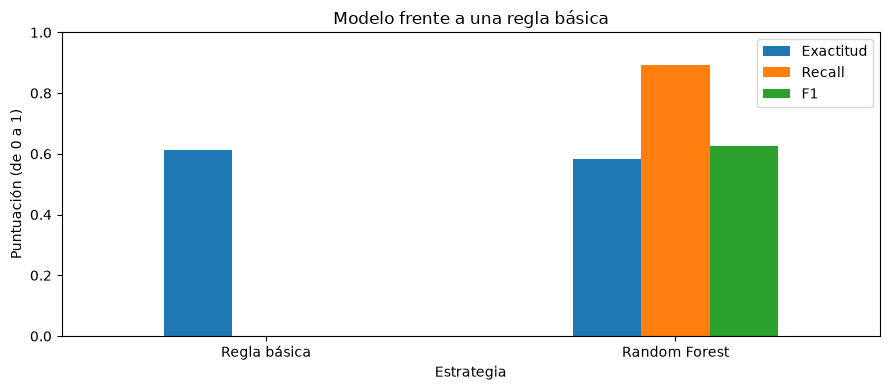

La regla básica acierta 61.3% de las reservas, pero detecta 0.0% de las cancelaciones.
En cambio, Random Forest acierta 58.4% en total y detecta 89.2% de las cancelaciones.
Por eso no escogeríamos el modelo mirando solamente la exactitud.


In [13]:
# La regla básica predice siempre la clase más frecuente en entrenamiento.
clase_frecuente = y_ent.value_counts().idxmax()
pred_basica = np.repeat(clase_frecuente, len(y_test))

comparacion_basica = pd.DataFrame([
    {
        "Estrategia": "Regla básica",
        "Exactitud": accuracy_score(y_test, pred_basica),
        "Precisión": precision_score(y_test, pred_basica, zero_division=0),
        "Recall": recall_score(y_test, pred_basica, zero_division=0),
        "F1": f1_score(y_test, pred_basica, zero_division=0)
    },
    {
        "Estrategia": modelo_elegido,
        "Exactitud": metricas_test["Exactitud"],
        "Precisión": metricas_test["Precisión"],
        "Recall": metricas_test["Recall"],
        "F1": metricas_test["F1"]
    }
])
display(comparacion_basica.round(4))

comparacion_basica.set_index("Estrategia")[["Exactitud", "Recall", "F1"]].plot(
    kind="bar", figsize=(9, 4), rot=0,
    title="Modelo frente a una regla básica"
)
plt.ylabel("Puntuación (de 0 a 1)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("La regla básica acierta", f"{comparacion_basica.iloc[0]['Exactitud']:.1%}",
      "de las reservas, pero detecta", f"{comparacion_basica.iloc[0]['Recall']:.1%}",
      "de las cancelaciones.")
print("En cambio,", modelo_elegido, "acierta", f"{metricas_test['Exactitud']:.1%}",
      "en total y detecta", f"{metricas_test['Recall']:.1%}", "de las cancelaciones.")
print("Por eso no escogeríamos el modelo mirando solamente la exactitud.")

### 5.2. ¿Y si el hotel solo puede revisar el 10 % o el 20 % de las reservas?

Con el umbral del modelo estamos marcando demasiadas reservas como riesgosas. Por eso probamos algo más cercano a una operación real: **ordenar las reservas según el riesgo estimado y revisar solo las primeras**.

Comparamos tres escenarios: revisar el **10 %**, el **20 %** o todas las reservas que superan el **umbral que ya elegimos en validación**. No cambiamos el modelo con estos resultados: solo mostramos qué pasaría si el hotel tuviera distintas capacidades de atención.

,Estrategia,Reservas revisadas,% revisadas,Cancelaciones detectadas,Falsas alertas,Precisión,Recall,Lift
0,Revisar 10 %,4069,0.1000,2712,1357,0.6665,0.1722,1.7223
1,Revisar 20 %,8138,0.2000,4679,3459,0.5750,0.2972,1.4858
2,Umbral 0.25,29281,0.7197,14052,15229,0.4799,0.8925,1.2401


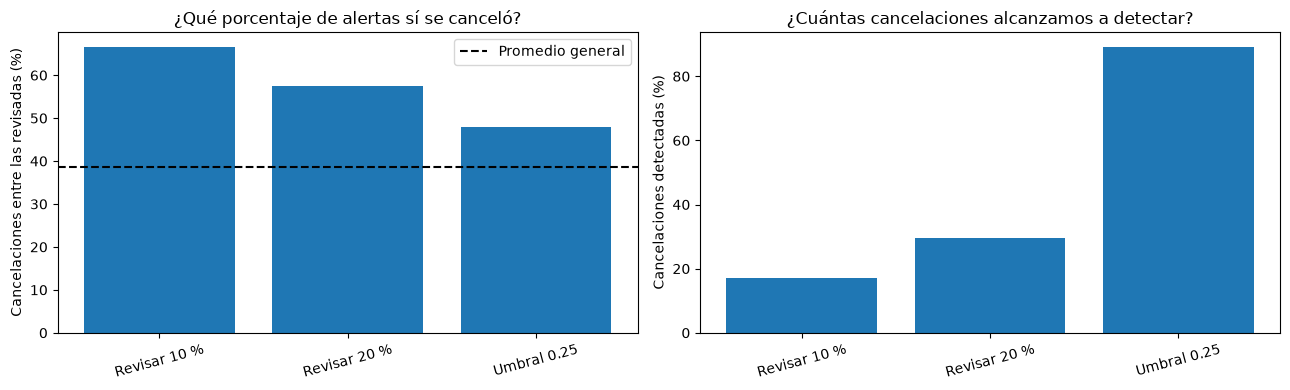

Si usamos Revisar 10 % revisaríamos 4069 reservas, detectaríamos 2712 cancelaciones y tendríamos 1357 falsas alertas.
Si usamos Revisar 20 % revisaríamos 8138 reservas, detectaríamos 4679 cancelaciones y tendríamos 3459 falsas alertas.
Si usamos Umbral 0.25 revisaríamos 29281 reservas, detectaríamos 14052 cancelaciones y tendríamos 15229 falsas alertas.
En el primer gráfico vemos qué tan concentradas están las cancelaciones en las reservas revisadas.
En el segundo vemos cuántas de todas las cancelaciones alcanzaríamos a detectar.
Revisar menos reservas reduce el trabajo y las falsas alertas, pero también deja pasar cancelaciones.
Estas cifras no prueban que contactar a los clientes evite una cancelación.


In [14]:
# Ordenamos las reservas de prueba según el riesgo calculado por el modelo.
ranking = pd.DataFrame({"real": y_test.to_numpy(), "riesgo": prob_test})
ranking = ranking.sort_values("riesgo", ascending=False)

# Una fila por cada opción de seguimiento del hotel.
escenarios = []
for porcentaje in [0.10, 0.20]:
    cantidad = int(np.ceil(len(ranking) * porcentaje))
    seleccionadas = ranking.head(cantidad)
    aciertos = int(seleccionadas["real"].sum())
    falsas_alertas = cantidad - aciertos
    escenarios.append({
        "Estrategia": f"Revisar {int(porcentaje * 100)} %",
        "Reservas revisadas": cantidad,
        "% revisadas": cantidad / len(ranking),
        "Cancelaciones detectadas": aciertos,
        "Falsas alertas": falsas_alertas,
        "Precisión": aciertos / cantidad,
        "Recall": aciertos / int(y_test.sum())
    })

# El umbral 0,25 ya estaba decidido: solo lo ponemos al lado para comparar.
alertas_umbral = int(pred_test.sum())
escenarios.append({
    "Estrategia": f"Umbral {umbral_elegido:.2f}",
    "Reservas revisadas": alertas_umbral,
    "% revisadas": alertas_umbral / len(pred_test),
    "Cancelaciones detectadas": int(vp),
    "Falsas alertas": int(fp),
    "Precisión": metricas_test["Precisión"],
    "Recall": metricas_test["Recall"]
})
seguimiento = pd.DataFrame(escenarios)
seguimiento["Lift"] = seguimiento["Precisión"] / y_test.mean()
display(seguimiento.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].bar(seguimiento["Estrategia"], seguimiento["Precisión"] * 100)
ejes[0].axhline(y_test.mean() * 100, color="black", linestyle="--", label="Promedio general")
ejes[0].set_title("¿Qué porcentaje de alertas sí se canceló?")
ejes[0].set_ylabel("Cancelaciones entre las revisadas (%)")
ejes[0].legend()

ejes[1].bar(seguimiento["Estrategia"], seguimiento["Recall"] * 100)
ejes[1].set_title("¿Cuántas cancelaciones alcanzamos a detectar?")
ejes[1].set_ylabel("Cancelaciones detectadas (%)")
for eje in ejes:
    eje.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

for _, fila in seguimiento.iterrows():
    print("Si usamos", fila["Estrategia"], "revisaríamos", int(fila["Reservas revisadas"]),
          "reservas, detectaríamos", int(fila["Cancelaciones detectadas"]),
          "cancelaciones y tendríamos", int(fila["Falsas alertas"]), "falsas alertas.")
print("En el primer gráfico vemos qué tan concentradas están las cancelaciones en las reservas revisadas.")
print("En el segundo vemos cuántas de todas las cancelaciones alcanzaríamos a detectar.")
print("Revisar menos reservas reduce el trabajo y las falsas alertas, pero también deja pasar cancelaciones.")
print("Estas cifras no prueban que contactar a los clientes evite una cancelación.")

# Conservamos esta comparación básica del 10 % con el resto para el informe.
primer_grupo = ranking.head(int(np.ceil(len(ranking) * 0.10)))
resto = ranking.iloc[len(primer_grupo):]
grupos_riesgo = pd.DataFrame({
    "Grupo": ["10 % de mayor riesgo", "Otras reservas"],
    "Reservas": [len(primer_grupo), len(resto)],
    "Tasa cancelación": [primer_grupo["real"].mean(), resto["real"].mean()]
})

### 5.3. Qué información usa más el modelo

Los árboles y Random Forest permiten ver cuáles variables utilizaron más para separar las reservas. Esto **no dice** que esas variables causen cancelaciones ni cuánto aumenta el riesgo de una reserva por tener cierto valor.


,importancia
previous_cancellations,0.381
lead_time,0.224
market_segment,0.147
arrival_date_month,0.054
hotel,0.051
distribution_channel,0.041
stays_in_week_nights,0.027
meal,0.023
reserved_room_type,0.016
stays_in_weekend_nights,0.011


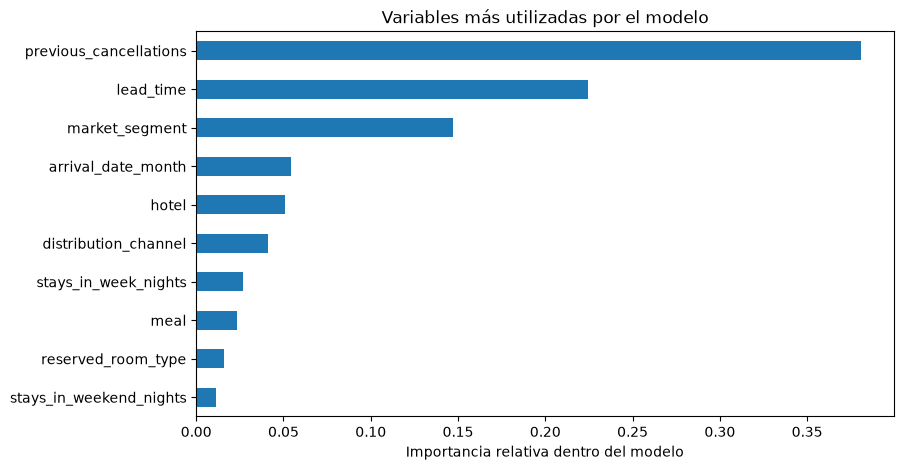

En este modelo las variables que más pesan son: previous_cancellations, lead_time, market_segment, arrival_date_month, hotel .
Esta medida favorece algunas variables con muchas posibilidades de división.
No indica la dirección del riesgo ni demuestra causalidad.


In [15]:
if hasattr(modelo_final, "feature_importances_"):
    importancia_columnas = pd.Series(modelo_final.feature_importances_, index=X_ent.columns)
    importancia_variables = {}
    for variable in variables:
        if variable in numericas:
            importancia_variables[variable] = importancia_columnas[variable]
        else:
            # Sumamos las columnas 0/1 que salieron de una misma categoría.
            columnas = [col for col in X_ent.columns if col.startswith(variable + "_")]
            importancia_variables[variable] = importancia_columnas[columnas].sum()
    importancias = pd.Series(importancia_variables).sort_values(ascending=False)
    display(importancias.head(10).round(3).to_frame("importancia"))
    importancias.head(10).sort_values().plot(kind="barh", figsize=(9, 5),
        title="Variables más utilizadas por el modelo")
    plt.xlabel("Importancia relativa dentro del modelo")
    plt.show()
    print("En este modelo las variables que más pesan son:",
          ", ".join(importancias.head(5).index), ".")
    print("Esta medida favorece algunas variables con muchas posibilidades de división.")
    print("No indica la dirección del riesgo ni demuestra causalidad.")
else:
    print("El modelo elegido fue regresión logística. Para mantener este notebook sencillo,",
          "no compararemos directamente los coeficientes como si fueran importancias.")
    print("Las tasas por grupo del EDA siguen siendo nuestra evidencia descriptiva.")

### 5.4. Volvemos a nuestra pregunta: ¿qué reservas se cancelan más?

No queremos terminar el trabajo diciendo solamente que Random Forest obtuvo un F1 determinado. También queremos responder **qué características aparecen con mayor frecuencia en grupos con mucha cancelación**.

Para que una categoría muy pequeña no encabece la tabla por casualidad, mostramos el grupo con mayor tasa en cada una de cinco características, **siempre que tenga al menos 1.000 reservas en entrenamiento**. Son grupos que se pueden cruzar entre sí: **no se suman sus porcentajes**. Las tasas describen lo observado, no prueban que una característica cause la cancelación.

,Característica,Grupo,Reservas,Tasa cancelación,Posible uso
0,Antecedentes de cancelación,Sí,5809,0.966604,Revisar si existe historial de cancelaciones.
1,Anticipación,181-365,7930,0.645902,Observar las reservas hechas con bastante anti...
2,Segmento comercial,Groups,10389,0.618539,Comparar el seguimiento entre segmentos.
3,Tipo de hotel,City Hotel,31623,0.416627,No asumir que ambos tipos de hotel tienen igua...
4,Canal de distribución,TA/TO,39824,0.396319,Revisar el comportamiento por canal.


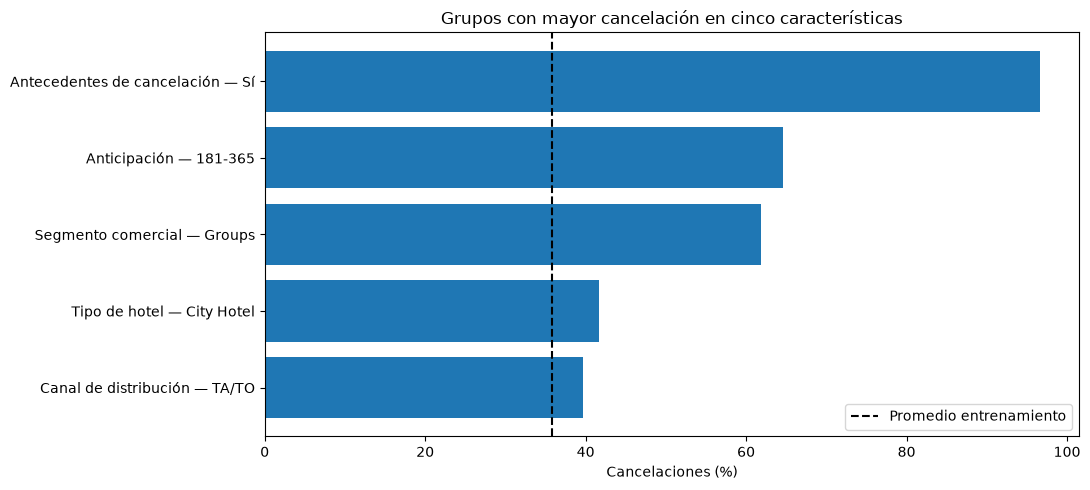

En antecedentes de cancelación destaca el grupo Sí con 96.7% de cancelaciones entre 5809 reservas.
En anticipación destaca el grupo 181-365 con 64.6% de cancelaciones entre 7930 reservas.
En segmento comercial destaca el grupo Groups con 61.9% de cancelaciones entre 10389 reservas.
En tipo de hotel destaca el grupo City Hotel con 41.7% de cancelaciones entre 31623 reservas.
En canal de distribución destaca el grupo TA/TO con 39.6% de cancelaciones entre 39824 reservas.
La línea muestra el promedio del entrenamiento: 35.8%
Estas tasas muestran asociaciones. No son cinco causas, ni se deben sumar entre sí.


In [16]:
# Tomamos los grupos del entrenamiento: es el periodo que usamos para aprender.
perfiles = entrenamiento.copy()
perfiles["rango_anticipacion"] = pd.cut(
    perfiles["lead_time"], bins=limites, labels=etiquetas)
perfiles["tuvo_cancelaciones_previas"] = np.where(
    perfiles["previous_cancellations"] > 0, "Sí", "No")

caracteristicas = {
    "Antecedentes de cancelación": "tuvo_cancelaciones_previas",
    "Anticipación": "rango_anticipacion",
    "Segmento comercial": "market_segment",
    "Tipo de hotel": "hotel",
    "Canal de distribución": "distribution_channel"
}
lecturas = {
    "Antecedentes de cancelación": "Revisar si existe historial de cancelaciones.",
    "Anticipación": "Observar las reservas hechas con bastante anticipación.",
    "Segmento comercial": "Comparar el seguimiento entre segmentos.",
    "Tipo de hotel": "No asumir que ambos tipos de hotel tienen igual comportamiento.",
    "Canal de distribución": "Revisar el comportamiento por canal."
}

filas_resumen = []
for nombre, columna in caracteristicas.items():
    tabla = perfiles.groupby(columna, observed=True)["is_canceled"].agg(["count", "mean"])
    tabla = tabla[tabla["count"] >= 1000].sort_values("mean", ascending=False)
    grupo = tabla.iloc[0]
    filas_resumen.append({
        "Característica": nombre,
        "Grupo": str(tabla.index[0]),
        "Reservas": int(grupo["count"]),
        "Tasa cancelación": float(grupo["mean"]),
        "Posible uso": lecturas[nombre]
    })

respuesta_negocio = pd.DataFrame(filas_resumen).sort_values("Tasa cancelación", ascending=False)
display(respuesta_negocio)

plt.figure(figsize=(11, 5))
etiquetas_grafico = respuesta_negocio["Característica"] + " — " + respuesta_negocio["Grupo"]
plt.barh(etiquetas_grafico, respuesta_negocio["Tasa cancelación"] * 100)
plt.axvline(y_ent.mean() * 100, color="black", linestyle="--", label="Promedio entrenamiento")
plt.xlabel("Cancelaciones (%)")
plt.title("Grupos con mayor cancelación en cinco características")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

for _, fila in respuesta_negocio.iterrows():
    print("En", fila["Característica"].lower(), "destaca el grupo", fila["Grupo"],
          "con", f"{fila['Tasa cancelación']:.1%}", "de cancelaciones entre",
          int(fila["Reservas"]), "reservas.")
print("La línea muestra el promedio del entrenamiento:", f"{y_ent.mean():.1%}")
print("Estas tasas muestran asociaciones. No son cinco causas, ni se deben sumar entre sí.")

## 6. Conclusiones

Nuestro objetivo era encontrar características relacionadas con las cancelaciones y comprobar si un modelo podía ayudar a **ordenar las reservas por riesgo**.

- La tabla de perfiles muestra cuáles grupos presentan tasas de cancelación más elevadas. Eso responde la primera parte de la pregunta de negocio.
- Random Forest ayuda a detectar cancelaciones, pero **una regla básica puede tener más exactitud** por predecir siempre la clase más frecuente. Por eso miramos F1, precisión y recall, no solo el porcentaje total de aciertos.
- Con el umbral de validación generamos muchas alertas. Los escenarios del 10 % y 20 % muestran el intercambio entre **cantidad de reservas que revisaría el hotel** y **cancelaciones que alcanzaría a detectar**.

**No demostramos que una variable cause una cancelación, ni que llamar a un cliente la evite.** Tampoco podemos confirmar que todas las variables estuvieran disponibles en el momento exacto de la reserva.

### 6.1. Guardamos las tablas que más nos sirven

Los gráficos y las conclusiones quedan dentro del notebook. Además, exportamos las tablas principales a la carpeta `resultados_crispdm/` para consultarlas sin abrir el notebook.

In [17]:
salida = Path("resultados_crispdm")
salida.mkdir(exist_ok=True)
periodos.to_csv(salida / "particiones.csv", index=False)
comparacion.to_csv(salida / "comparacion_modelos.csv", index=False)
pd.DataFrame([metricas_test]).to_csv(salida / "evaluacion_test.csv", index=False)
comparacion_basica.to_csv(salida / "comparacion_regla_basica.csv", index=False)
seguimiento.to_csv(salida / "escenarios_seguimiento.csv", index=False)
respuesta_negocio.to_csv(salida / "respuesta_negocio.csv", index=False)
grupos_riesgo.to_csv(salida / "grupos_riesgo_test.csv", index=False)
if "importancias" in globals():
    importancias.to_csv(salida / "importancia_modelo.csv", header=["importancia"])
print("Guardamos las tablas en", salida)

Guardamos las tablas en resultados_crispdm


### Nota de reproducibilidad

- Ejecutar el notebook desde la primera celda con el archivo `hotel_bookings.csv` en la misma carpeta.
- Las cifras de la presentación corresponden a esta ejecución; si cambia el código o el archivo de datos, hay que volver a ejecutar y actualizar.
- La separación temporal usa la fecha prevista de llegada, no la fecha de la reserva; es una limitación que se debe mencionar al presentar.

En esta versión damos prioridad a **F1, precisión, recall, matriz de confusión y ROC-AUC**, las métricas de clasificación vistas en clase.